In [42]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

In [43]:
# Load the dataset
data = pd.read_csv('placement.csv')
data.head()

,Unnamed: 0,cgpa,iq,placement
0,0,6.8,123.0,1
1,1,5.9,106.0,0
2,2,5.3,121.0,0
3,3,7.4,132.0,1
4,4,5.8,142.0,0


# Preprocessing

In [44]:
data = data.iloc[:, 1:]

In [45]:
data.head()

,cgpa,iq,placement
0,6.8,123.0,1
1,5.9,106.0,0
2,5.3,121.0,0
3,7.4,132.0,1
4,5.8,142.0,0


In [46]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   cgpa       100 non-null    float64
 1   iq         100 non-null    float64
 2   placement  100 non-null    int64  
dtypes: float64(2), int64(1)
memory usage: 2.5 KB


In [47]:
data.isna().sum()

cgpa         0
iq           0
placement    0
dtype: int64

In [48]:
data.isna()

,cgpa,iq,placement
0,False,False,False
1,False,False,False
2,False,False,False
3,False,False,False
4,False,False,False
...,...,...,...
95,False,False,False
96,False,False,False
97,False,False,False
98,False,False,False


In [49]:
data.describe()

,cgpa,iq,placement
count,100.000000,100.000000,100.000000
mean,5.991000,123.580000,0.500000
std,1.143634,39.944198,0.502519
min,3.300000,37.000000,0.000000
25%,5.075000,101.500000,0.000000
50%,6.000000,127.500000,0.500000
75%,6.900000,149.000000,1.000000
max,8.500000,233.000000,1.000000


# EDA

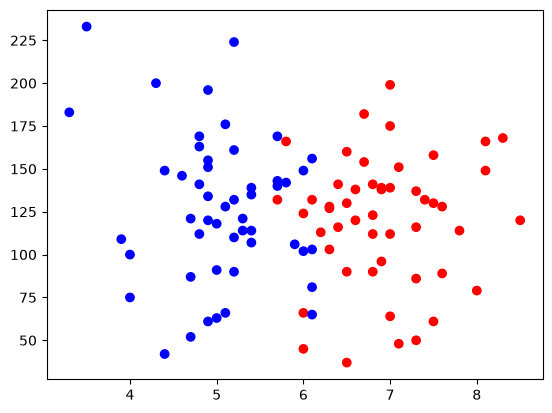

In [50]:
plt.scatter(data['cgpa'], data['iq'], c=data['placement'], cmap='bwr')

# Feature Selection

In [51]:
# not needed for this dataset as its a toy dataset but in real world datasets we need to check for missing values and handle them accordingly.

In [52]:
x = data.drop('placement', axis=1)

In [53]:
y = data['placement']

# Train test Split

In [54]:
X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.1, random_state=20)

In [55]:
X_train

,cgpa,iq
76,4.9,155.0
93,6.8,112.0
88,4.4,149.0
92,5.2,110.0
5,7.1,48.0
...,...,...
28,5.2,90.0
95,4.3,200.0
15,5.1,176.0
90,7.3,86.0


In [56]:
X_test

,cgpa,iq
70,6.3,127.0
74,6.7,154.0
2,5.3,121.0
44,7.5,61.0
56,6.1,65.0
48,6.6,138.0
12,5.4,139.0
36,5.7,140.0
0,6.8,123.0
49,5.4,135.0


# Scale the data

In [57]:
from sklearn.preprocessing import StandardScaler

In [58]:
scaler = StandardScaler()

In [59]:
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [60]:
X_train

array([[-9.10591581e-01,  7.63741454e-01],
       [ 7.06346740e-01, -2.93746713e-01],
       [-1.33610167e+00,  6.16184966e-01],
       [-6.55285530e-01, -3.42932209e-01],
       [ 9.61652791e-01, -1.86768259e+00],
       [ 1.13185682e+00, -1.81849709e+00],
       [-1.08079561e+00, -9.08565415e-01],
       [ 2.80836656e-01,  9.97372561e-02],
       [-2.29775446e-01,  1.98108248e-01],
       [ 4.51040690e-01,  8.86705194e-01],
       [ 1.81267296e+00,  6.16184966e-01],
       [-9.95693598e-01,  4.19442981e-01],
       [ 7.06346740e-01, -8.34787171e-01],
       [ 1.81267296e+00,  1.03426168e+00],
       [-1.76161175e+00, -3.67524957e-01],
       [ 9.61652791e-01,  6.65370462e-01],
       [-5.95714118e-02, -4.41303202e-01],
       [-1.33610167e+00, -2.01523908e+00],
       [ 2.15308103e+00, -9.70047285e-02],
       [-6.55285530e-01,  1.98108248e-01],
       [-1.16589763e+00,  5.42406721e-01],
       [ 8.76550774e-01, -1.47419862e+00],
       [ 1.13185682e+00, -1.95375721e-01],
       [ 7.

In [61]:
X_test

array([[ 0.28083666,  0.07514451],
       [ 0.62124472,  0.73914871],
       [-0.57018351, -0.07241198],
       [ 1.30206086, -1.54797686],
       [ 0.11063262, -1.44960587],
       [ 0.53614271,  0.34566474],
       [-0.4850815 ,  0.37025748],
       [-0.22977545,  0.39485023],
       [ 0.70634674, -0.02322648],
       [-0.4850815 ,  0.27188649]])

# Train model

In [62]:
from sklearn.linear_model import LogisticRegression

In [63]:
model = LogisticRegression()

In [64]:
model.fit(X_train, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

# Evaluate

In [65]:
model.predict(X_test)

array([1, 1, 0, 1, 1, 1, 0, 0, 1, 0])

In [66]:
y_test

70    1
74    1
2     0
44    1
56    0
48    1
12    0
36    0
0     1
49    0
Name: placement, dtype: int64

In [67]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [68]:
accuracy_score(y_test, model.predict(X_test))

0.9

In [69]:
confusion_matrix(y_test, model.predict(X_test))

array([[4, 1],
       [0, 5]])

In [70]:
classification_report(y_test, model.predict(X_test))

'              precision    recall  f1-score   support\n\n           0       1.00      0.80      0.89         5\n           1       0.83      1.00      0.91         5\n\n    accuracy                           0.90        10\n   macro avg       0.92      0.90      0.90        10\nweighted avg       0.92      0.90      0.90        10\n'

In [71]:
from mlxtend.plotting import plot_decision_regions

<Axes: >

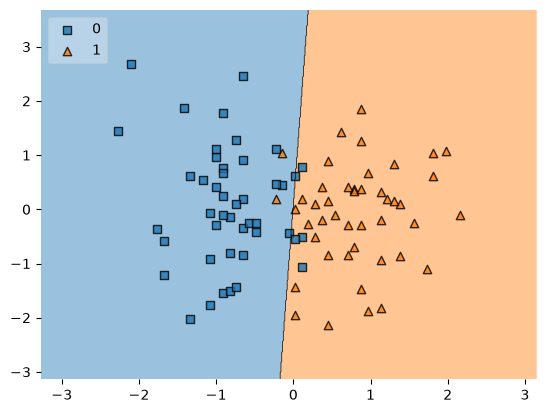

In [72]:
plot_decision_regions(X_train, y_train.values, clf=model, legend=2)

In [73]:
import pickle as pkl

In [74]:
pkl.dump(model, open('model.pkl', 'wb'))

# Deploy the model